In [49]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt

In [50]:
df = pd.read_csv("tire_pressure_dataset_DXB_vehicle.csv")
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df.set_index('Timestamp', inplace=True)

In [51]:
df.head()

,Tire_Pressure_PSI
Timestamp,
2022-04-24 12:59:00,31.86
2022-04-24 17:59:00,31.81
2022-04-24 22:59:00,31.70
2022-04-25 03:59:00,31.59
2022-04-25 08:59:00,31.45


In [52]:
df.describe()

,Tire_Pressure_PSI
count,5000.000000
mean,27.532020
std,3.188681
min,21.870000
25%,24.800000
50%,27.620000
75%,30.290000
max,32.950000


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5000 entries, 2022-04-24 12:59:00 to 2025-02-28 23:59:00
Data columns (total 1 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Tire_Pressure_PSI  5000 non-null   float64
dtypes: float64(1)
memory usage: 78.1 KB


In [55]:
def create_features(df):
    df["Hour"] = df.index.hour
    df["DayOfWeek"] = df.index.dayofweek
    df["Month"] = df.index.month
    df["isWeekend"] = df["DayOfWeek"].apply(lambda x: 1 if x >= 5 else 0)
    df["isRushHour"] = df["Hour"].apply(lambda x: 1 if 7 <= x <= 9 or 17 <= x <= 19 else 0)
    # Cyclical encoding for temporal features
    df['hour_sin'] = np.sin(2 * np.pi * df['Hour']/24)
    df['hour_cos'] = np.cos(2 * np.pi * df['Hour']/24)
    df['day_sin'] = np.sin(2 * np.pi * df['DayOfWeek']/7)
    df['day_cos'] = np.cos(2 * np.pi * df['DayOfWeek']/7)
    df['month_sin'] = np.sin(2 * np.pi * (df['Month']-1)/12)
    df['month_cos'] = np.cos(2 * np.pi * (df['Month']-1)/12)
    
    # Lag features
    df['tp_lag_24h'] = df['Tire_Pressure_PSI'].shift(24)
    df['tp_rolling_avg_3d'] = df['Tire_Pressure_PSI'].rolling(window=72).mean()
    
    # Drop original columns and NAs
    df.drop(['Hour', 'DayOfWeek', 'Month'], axis=1, inplace=True)
    df.dropna(inplace=True)
    return df

In [59]:
df = create_features(df)

# Define features and target
features = ['Tire_Pressure_PSI', 'isWeekend', 'isRushHour',
            'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
            'month_sin', 'month_cos', 'tp_lag_24h',
            'tp_rolling_avg_3d']
target = 'Tire_Pressure_PSI'

In [60]:
train_size = int(len(df) * 0.8)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

In [61]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_df[features])
test_scaled = scaler.transform(test_df[features])

In [64]:
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data)-window_size-24):  # Predict 24h ahead
        X.append(data[i:i+window_size])
        y.append(data[i+window_size:i+window_size+24, 0])  # Next 24 temperatures
    return np.array(X), np.array(y)

In [65]:
window_size = 35  # 1 week lookback
X_train, y_train = create_sequences(train_scaled, window_size)
X_test, y_test = create_sequences(test_scaled, window_size)

In [66]:
X_train.shape, y_train.shape

((3827, 35, 11), (3827, 24))

In [67]:
from tensorflow.keras.layers import Bidirectional, BatchNormalization

model = Sequential([
    # Bidirectional LSTM to capture forward/backward patterns
    Bidirectional(LSTM(128, return_sequences=True), input_shape=(window_size, len(features))),
    BatchNormalization(),  # Stabilizes training
    Dropout(0.2),  # Slightly higher dropout for regularization

    # Stacked LSTM with reduced units
    Bidirectional(LSTM(64, return_sequences=True)),
    BatchNormalization(),
    Dropout(0.3),

    # Final LSTM layer
    LSTM(32),
    
    # Intermediate dense layer for non-linear mapping
    Dense(64, activation='relu'),
    Dropout(0.2),
    
    # Output layer for 24-hour prediction
    Dense(24)
])

In [68]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [69]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train,
                    epochs=30,
                    batch_size=32,
                    validation_split=0.1,
                    verbose=1,
                    callbacks=[early_stopping])

Epoch 1/30
108/108 [==============================] - 14s 60ms/step - loss: 0.0938 - mae: 0.2246 - val_loss: 0.0418 - val_mae: 0.1500
Epoch 2/30
108/108 [==============================] - 5s 44ms/step - loss: 0.0438 - mae: 0.1465 - val_loss: 0.0378 - val_mae: 0.1448
Epoch 3/30
108/108 [==============================] - 5s 45ms/step - loss: 0.0344 - mae: 0.1256 - val_loss: 0.0200 - val_mae: 0.0941
Epoch 4/30
108/108 [==============================] - 5s 45ms/step - loss: 0.0298 - mae: 0.1145 - val_loss: 0.0165 - val_mae: 0.0704
Epoch 5/30
108/108 [==============================] - 5s 44ms/step - loss: 0.0264 - mae: 0.1063 - val_loss: 0.0106 - val_mae: 0.0592
Epoch 6/30
108/108 [==============================] - 5s 46ms/step - loss: 0.0243 - mae: 0.1008 - val_loss: 0.0136 - val_mae: 0.0526
Epoch 7/30
108/108 [==============================] - 5s 44ms/step - loss: 0.0231 - mae: 0.0969 - val_loss: 0.0140 - val_mae: 0.0671
Epoch 8/30
108/108 [==============================] - 5s 46ms/step -

In [70]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}')

29/29 [==============================] - 1s 20ms/step - loss: 0.0163 - mae: 0.0602
Test Loss: 0.0163, Test MAE: 0.0602


In [71]:
def inverse_scale_predictions(scaled_predictions, scaler, feature_index=0):
    # Get the number of samples and steps
    n_samples, n_steps = scaled_predictions.shape
    
    # Create a dummy array with the same shape as the original data
    dummy = np.zeros((n_samples * n_steps, len(features)))
    
    # Fill the target feature column with the predictions
    dummy[:, feature_index] = scaled_predictions.flatten()
    
    # Inverse transform the dummy array
    inverse_scaled = scaler.inverse_transform(dummy)
    
    # Reshape back to (n_samples, n_steps)
    return inverse_scaled[:, feature_index].reshape(n_samples, n_steps)

In [ ]:
# Make predictions
test_predictions = model.predict(X_test[:1])  # Predict first test sample
test_predictions = inverse_scale_predictions(test_predictions, scaler)

# Get the corresponding timestamps for the predictions
prediction_timestamps = test_df.index[window_size:window_size+24]

1/1 [==============================] - 0s 67ms/step


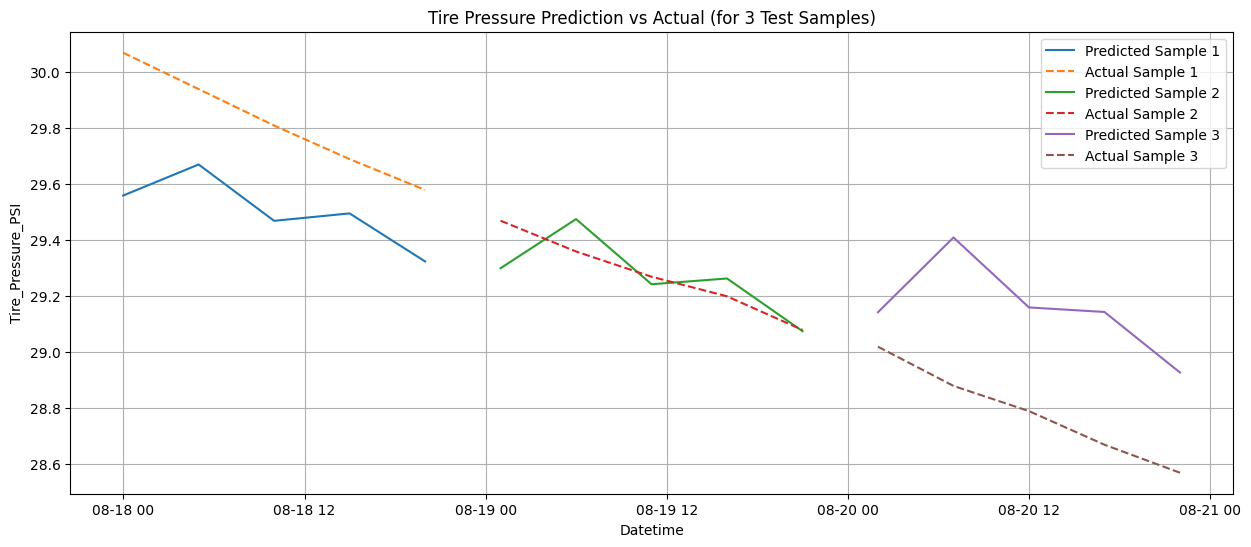

In [96]:
import matplotlib.pyplot as plt
import numpy as np

# Function to inverse scale predictions correctly
def inverse_scale_predictions(predictions, scaler):
    """
    Inverse transform the predicted values for a single target column.
    """
    predictions = predictions.reshape(-1, 1)  # Ensure correct shape
    return scaler.inverse_transform(np.hstack([predictions, np.zeros((predictions.shape[0], len(features) - 1))]))[:, 0]

# Predict for first 3 test samples
num_samples = 3
plt.figure(figsize=(15, 6))

for i in range(num_samples):
    # Predict using the model
    test_predictions = model.predict(X_test[i:i+1], verbose=0)  # Shape (1, 24)
    test_predictions = inverse_scale_predictions(test_predictions, scaler)  # Convert back to original scale

    # Ensure shape matches
    test_predictions = test_predictions.flatten()[:5]  # Take only 5 values

    # Get the corresponding timestamps
    start_idx = window_size + i * 5  # Adjust index for 5 readings per day
    prediction_timestamps = test_df.index[start_idx:start_idx + 5]  # Next 5 timestamps

    # Ensure timestamp shape matches prediction
    if len(test_predictions) == len(prediction_timestamps):
        plt.plot(prediction_timestamps, test_predictions, label=f'Predicted Sample {i+1}')
    
    # Plot actual values
    actual_values = test_df['Tire_Pressure_PSI'].iloc[start_idx:start_idx + 5]
    plt.plot(actual_values.index, actual_values.values, label=f'Actual Sample {i+1}', linestyle='dashed')

# Plot settings
plt.title('Tire Pressure Prediction vs Actual (for 3 Test Samples)')
plt.xlabel('Datetime')
plt.ylabel('Tire_Pressure_PSI')
plt.legend()
plt.grid(True)
plt.show()


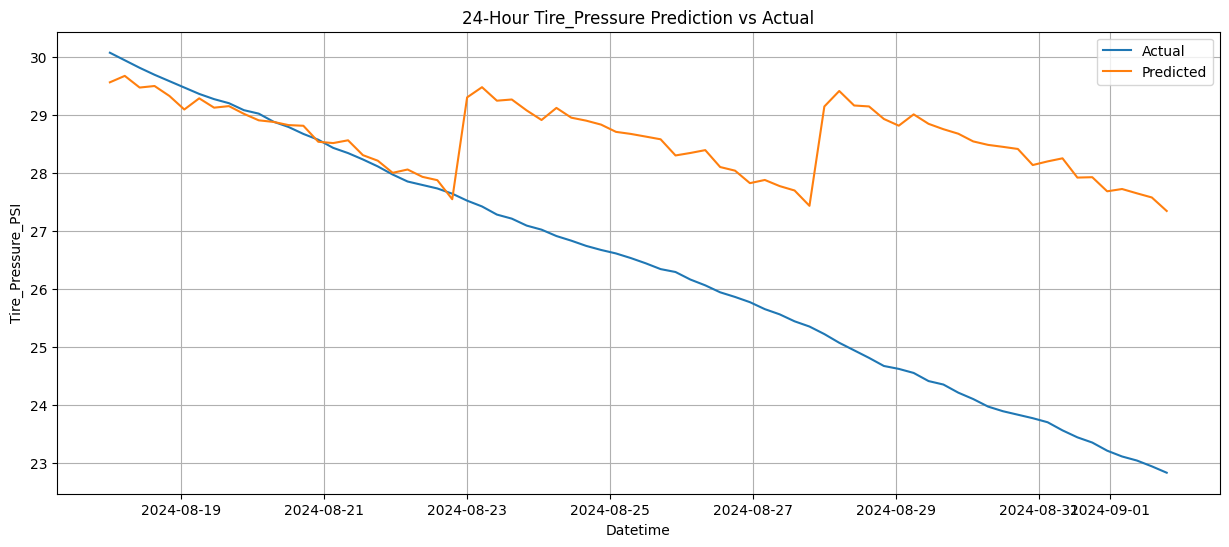

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(test_df.index[window_size:window_size+24], test_df['Tire_Pressure_PSI'].iloc[window_size:window_size+24], label='Actual')
plt.plot(test_df.index[window_size:window_size+24], test_predictions.flatten(), label='Predicted')  # Flatten predictions
plt.title('24-Hour Tire_Pressure Prediction vs Actual')
plt.xlabel('Datetime')
plt.ylabel('Tire_Pressure_PSI')
plt.legend()
plt.grid(True)
plt.show()

In [83]:
# Function to generate predictions for a given period
def predict_for_period(model, scaler, df, start_index, period_days, window_size, features):
    """
    Generate predictions for a specific period.
    
    Args:
        model: Trained LSTM model
        scaler: Fitted MinMaxScaler
        df: DataFrame containing the data
        start_index: Index to start predictions from
        period_days: Number of days to predict
        window_size: Lookback window size
        features: List of feature names
    
    Returns:
        A tuple of (timestamps, actual_values, predicted_values)
    """
    # Calculate the number of hours in the period
    period_hours = period_days * 5  # 5 samples per hour
    
    # Initialize lists to store predictions and actual values
    predictions = []
    actual_values = df['Tire_Pressure_PSI'].iloc[start_index:start_index + period_hours].values
    
    # Iterate through the period and make predictions
    for i in range(period_hours):
        # Get the input sequence
        input_seq = df[features].iloc[start_index + i:start_index + i + window_size].values
        input_seq_scaled = scaler.transform(input_seq)
        input_seq_scaled = np.expand_dims(input_seq_scaled, axis=0)  # Add batch dimension
        
        # Predict the next 24 hours
        pred = model.predict(input_seq_scaled,verbose=0)
        pred = inverse_scale_predictions(pred, scaler)  # Inverse scale predictions
        predictions.append(pred[0, 0])  # Append the first predicted value
    
    # Get timestamps for the period
    timestamps = df.index[start_index:start_index + period_hours]
    
    return timestamps, actual_values, np.array(predictions)

In [84]:
# Function to plot predictions vs actual values
def plot_predictions(timestamps, actual_values, predicted_values, title):
    """
    Plot actual vs predicted values.
    
    Args:
        timestamps: Timestamps for the x-axis
        actual_values: Actual temperature values
        predicted_values: Predicted temperature values
        title: Plot title
    """
    plt.figure(figsize=(15, 6))
    plt.plot(timestamps, actual_values, label='Actual', color='blue')
    plt.plot(timestamps, predicted_values, label='Predicted', color='red', linestyle='--')
    plt.title(title)
    plt.xlabel('Datetime')
    plt.ylabel('Tire_Pressure_PSI')
    plt.legend()
    plt.grid(True)
    plt.show()

In [85]:
import warnings
warnings.filterwarnings('ignore')  # Suppress warnings

In [86]:
# Example: Predict for 1 month (30 days) from a specific start index
start_index = 4000  # Example start index (can be from train or test set)
period_days = 30  # Predict for 30 days (1 month)
timestamps, actual_values, predicted_values = predict_for_period(
    model, scaler, df, start_index, period_days, window_size, features
)

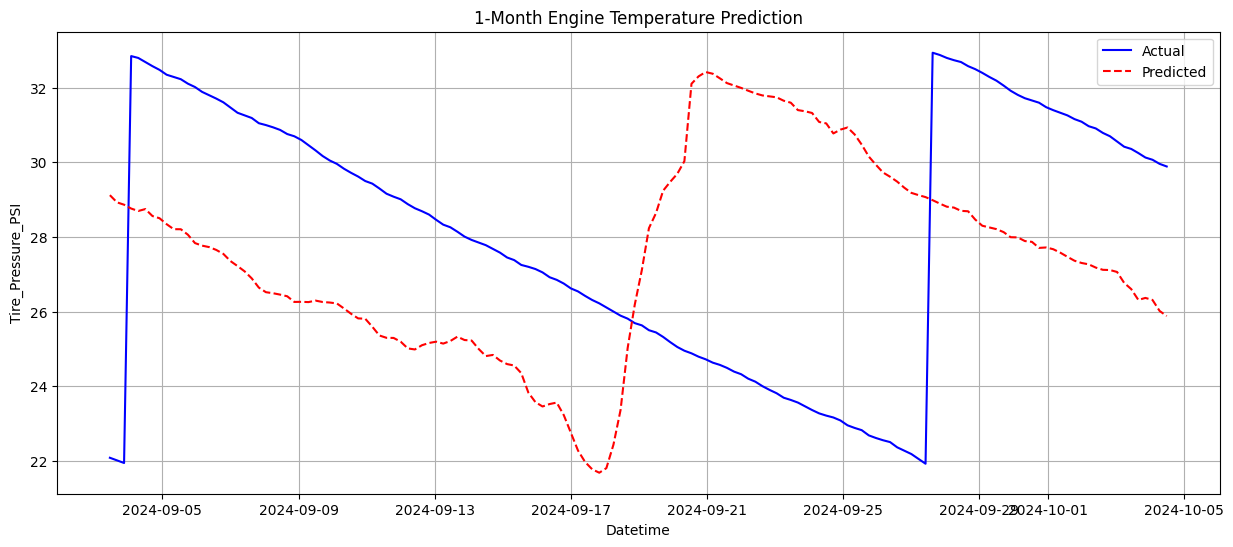

In [87]:
# Plot the results
plot_predictions(timestamps, actual_values, predicted_values, title='1-Month Engine Temperature Prediction')

In [88]:
# Make predictions for 5 days (120 hours)
test_predictions = model.predict(X_test[:5], verbose=0)  # Predict first 5 test samples
test_predictions = inverse_scale_predictions(test_predictions, scaler)

# Get timestamps and flatten predictions
prediction_timestamps = test_df.index[window_size:window_size+120]
test_predictions_flat = test_predictions.flatten()

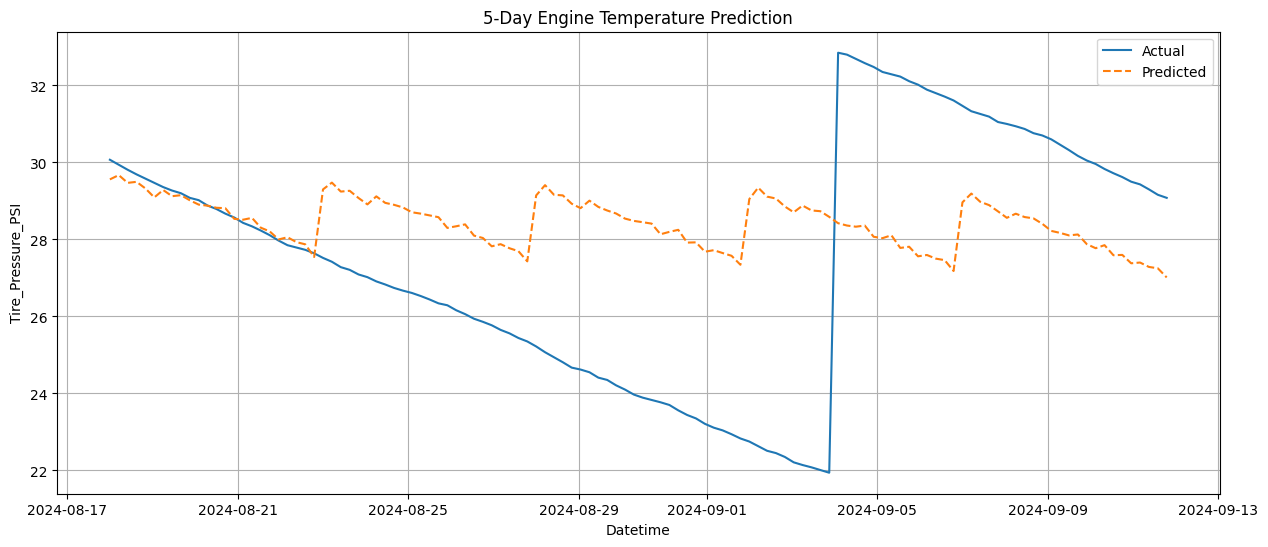

In [89]:
# Plot results
plt.figure(figsize=(15, 6))
plt.plot(prediction_timestamps,
         test_df['Tire_Pressure_PSI'].iloc[window_size:window_size+120], 
         label='Actual')
plt.plot(prediction_timestamps, 
         test_predictions_flat, 
         label='Predicted',
         linestyle='--')
plt.title('5-Day Engine Temperature Prediction')
plt.xlabel('Datetime')
plt.ylabel('Tire_Pressure_PSI')
plt.legend()
plt.grid(True)
plt.show()

In [90]:
model.save("final_model_tyrepressure.h5") 